# CALOR Y MAYORES EN MADRID

"En verano, Madrid no es igual de caliente para todos. Este proyecto mide cuánto calor soportan las residencias y centros de mayores de la ciudad, qué encuentran sus usuarios en 15 minutos andando, y propone dónde actuar primero."
Pregunta central: ¿qué centros de mayores de Madrid están más expuestos al calor y peor protegidos en su entorno, y qué intervenciones (arbolado, fuentes, refugios) mejorarían más su situación?


Objetivo, unidad de análisis e hipótesis
Objetivo: identificar qué residencias, centros de día y centros municipales de mayores de Madrid soportan más calor y tienen peor protección en su entorno, y recomendar dónde intervenir primero.
Unidad de análisis: cada centro (un punto en el mapa) y su isócrona de 15 minutos andando. La temperatura se modela en hexágonos H3 de unos 0,1 km² para toda la ciudad.
Clientes de las recomendaciones: la Comunidad de Madrid, que planifica plazas y centros; el Ayuntamiento, que decide refugios y arbolado; y los operadores de residencias.
1.	¿Qué hace que una zona sea más caliente? H1: la vegetación y la forma de los edificios explican la mayor parte de la temperatura de superficie.
2.	¿Están los centros en zonas más calientes que el resto de la ciudad? H2: el entorno de los centros no es más fresco que la media residencial, y varía por tipo de centro y titularidad (pública o privada). Contrastes: Mann-Whitney y Kruskal-Wallis.
3.	¿Tiene cada centro un entorno protector a 15 minutos? H3: muchos centros no alcanzan sombra suficiente, fuentes ni refugios andando a 0,8 m/s.
4.	¿Dónde actuar? H4: unas pocas intervenciones bien situadas mejorarían mucho la isócrona confortable de los centros más expuestos.


Isócronas: los 15 minutos a paso de persona mayor
2 ESCENARIOS:
CON Y SIN INVERVENCION

DEMO EN STREAMLIT, AGREGANDO ARBOLADO, CUANTOS GRADOS BAJA LA TEMPERATURA

In [ ]:
El modelo aprende cómo influye la forma urbana en la temperatura y, una vez entrenado, funciona como simulador de intervenciones.

## Recolección de datos: red peatonal y parques (OpenStreetMap)

**Fuente:** OpenStreetMap, descargado con `osmnx`.

In [ ]:
%pip install osmnx

In [3]:
import geopandas as gpd
import osmnx as ox

area de estudio(termino municipal +2km)

In [10]:
municipality = gpd.read_file("../raw/limites/termino_municipal/TERMINO_MUNICIPAL.shp")
study_area = municipality.buffer(2000)
study_area_wgs84 = study_area.to_crs(epsg=4326)
polygon = study_area_wgs84.iloc[0]
municipality.crs

<Projected CRS: EPSG:25830>
Name: ETRS89 / UTM zone 30N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Europe between 6°W and 0°W: Faroe Islands offshore; Ireland - offshore; Jan Mayen - offshore; Norway including Svalbard - offshore; Spain - mainland - onshore and offshore.
- bounds: (-6.0, 35.26, 0.01, 80.49)
Coordinate Operation:
- name: UTM zone 30N
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

red peatonal

In [11]:
walk_graph = ox.graph_from_polygon(polygon, network_type="walk")
print("Nodos (cruces):", len(walk_graph.nodes))
print("Aristas (tramos):", len(walk_graph.edges))

Nodos (cruces): 220894
Aristas (tramos): 668278


guardar la red

In [12]:
ox.save_graphml(walk_graph, "../raw/osm/walk_graph_madrid.graphml")

parques

In [13]:
parks = ox.features_from_polygon(polygon, tags={"leisure": "park"})
parks = parks[parks.geometry.type.isin(["Polygon", "MultiPolygon"])].reset_index()
print("Parques:", parks.shape[0])
parks[["name", "geometry"]].head()

Parques: 2991


,name,geometry
0,Parque del Oeste,"POLYGON ((-3.71567 40.42411, -3.71564 40.42411..."
1,Parque de Don David Pérez y Don Miguel Ángel H...,"MULTIPOLYGON (((-3.63389 40.46134, -3.63385 40..."
2,Jardines del Campo del Moro,"POLYGON ((-3.72052 40.41569, -3.72051 40.41574..."
3,Parque de Atenas,"POLYGON ((-3.72052 40.41569, -3.71711 40.41539..."
4,NaN,"POLYGON ((-3.65415 40.3769, -3.65415 40.37691,..."


guardar los parques

In [14]:
parks[["id", "name", "geometry"]].to_file("../raw/osm/parks_madrid.gpkg", driver="GPKG")

mapa de comprobacion

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

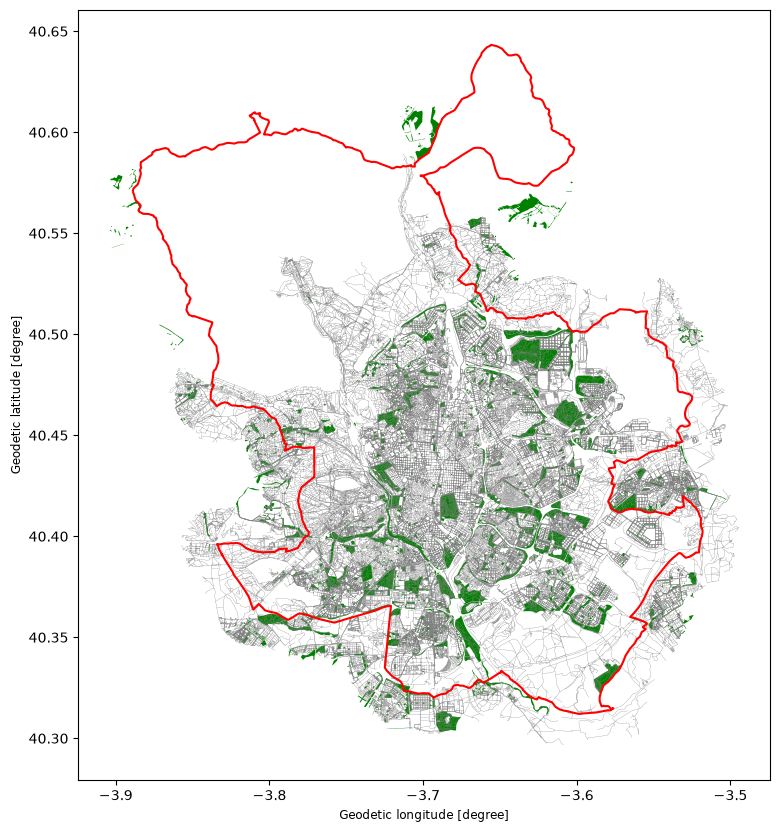

In [15]:
nodes, edges = ox.graph_to_gdfs(walk_graph)
ax = edges.plot(linewidth=0.1, color="grey", figsize=(10, 10))
parks.plot(ax=ax, color="green")
municipality.to_crs(epsg=4326).boundary.plot(ax=ax, color="red")